# Business Objective – Home Credit Application Dataset

## Business Objective

Home Credit provides loans to customers who may have limited or no traditional credit history. The main business objective is to analyze loan applicant information and identify meaningful groups of applicants with similar financial, demographic, employment, and credit-related characteristics.

Using clustering techniques, the goal is to discover hidden customer segments without using a predefined target variable.

## Clustering Objectives

1. **Applicant Segmentation**
   - Group loan applicants based on similar financial and demographic characteristics.
   - Identify distinct types of credit applicants.

2. **Income-Based Segmentation**
   - Group applicants based on total income, loan amount, annuity amount, and other financial attributes.
   - Understand differences between low-, medium-, and high-income applicant groups.

3. **Credit Profile Segmentation**
   - Identify applicants with similar credit requirements.
   - Analyze relationships between requested credit amount, income, annuity, and goods price.

4. **Employment Profile Analysis**
   - Segment applicants based on employment-related characteristics.
   - Understand how employment duration, occupation, and income source differ across clusters.

5. **Demographic Segmentation**
   - Identify applicant groups based on age, family size, education, housing type, and other demographic characteristics.

6. **Financial Burden Analysis**
   - Identify groups with different levels of financial burden.
   - Analyze indicators such as:
     - Credit-to-Income Ratio
     - Annuity-to-Income Ratio
     - Credit-to-Goods-Price Ratio

7. **Potential Risk-Pattern Discovery**
   - Discover applicant groups whose characteristics may warrant different levels of credit review.
   - Clustering itself should not be treated as a loan-default prediction model because the test dataset does not contain the target/default label.

8. **Outlier Detection**
   - Identify applicants with unusual income, credit, annuity, employment, or demographic characteristics.
   - Detect applicants significantly different from the majority of customers.

9. **Business Decision Support**
   - Support customer segmentation and portfolio analysis.
   - Help design differentiated loan products and customer communication strategies.
   - Provide additional insights that can complement supervised credit-risk models.

## Machine Learning Objective

Apply unsupervised machine learning algorithms such as:

- K-Means Clustering
- Hierarchical / Agglomerative Clustering
- DBSCAN
- Mean Shift Clustering

Evaluate the quality of the generated clusters using:

- Elbow Method
- Silhouette Score
- Davies-Bouldin Index
- Calinski-Harabasz Score
- Cluster Visualization

## Expected Outcome

The expected outcome is to divide Home Credit loan applicants into meaningful customer segments based on similarities in their financial, demographic, employment, and credit characteristics.

These clusters can then be profiled to understand different types of loan applicants and support portfolio analysis, customer segmentation, credit review, and business strategy.

In [1]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import pandas as pd 
import numpy as np 
from sklearn.cluster import KMeans, AgglomerativeClustering, MeanShift, DBSCAN

insurance_dataset = pd.read_excel(
    r"C:\Users\Navitha\Downloads\application_test.xlsx"
)

In [3]:
insurance_dataset=insurance_dataset[['AMT_CREDIT','AMT_ANNUITY','AMT_GOODS_PRICE','DAYS_BIRTH','DAYS_EMPLOYED','DAYS_REGISTRATION','DAYS_ID_PUBLISH','CNT_FAM_MEMBERS']]

In [4]:
insurance_dataset.shape

(48744, 8)

In [5]:
insurance_dataset.isna().sum()

AMT_CREDIT            0
AMT_ANNUITY          24
AMT_GOODS_PRICE       0
DAYS_BIRTH            0
DAYS_EMPLOYED         0
DAYS_REGISTRATION     0
DAYS_ID_PUBLISH       0
CNT_FAM_MEMBERS       0
dtype: int64

In [6]:
def fill_null_values(df):
    for column in df.columns:
        if df[column].isna().sum() > 0:
            if df[column].dtype in ['int64', 'float64']:
                df[column] = df[column].fillna(df[column].median())

    return df

insurance_dataset = fill_null_values(insurance_dataset)

insurance_dataset.isna().sum()

AMT_CREDIT           0
AMT_ANNUITY          0
AMT_GOODS_PRICE      0
DAYS_BIRTH           0
DAYS_EMPLOYED        0
DAYS_REGISTRATION    0
DAYS_ID_PUBLISH      0
CNT_FAM_MEMBERS      0
dtype: int64

In [7]:
insurance_dataset


,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,CNT_FAM_MEMBERS
0,568800.0,20560.5,450000.0,-19241,-2329,-5170,-812,2
1,222768.0,17370.0,180000.0,-18064,-4469,-9118,-1623,2
2,663264.0,69777.0,630000.0,-20038,-4458,-2175,-3503,2
3,1575000.0,49018.5,1575000.0,-13976,-1866,-2000,-4208,4
4,625500.0,32067.0,625500.0,-13040,-2191,-4000,-4262,3
...,...,...,...,...,...,...,...,...
48739,412560.0,17473.5,270000.0,-19970,-5169,-9094,-3399,1
48740,622413.0,31909.5,495000.0,-11186,-1149,-3015,-3003,4
48741,315000.0,33205.5,315000.0,-15922,-3037,-2681,-1504,3
48742,450000.0,25128.0,450000.0,-13968,-2731,-1461,-1364,2


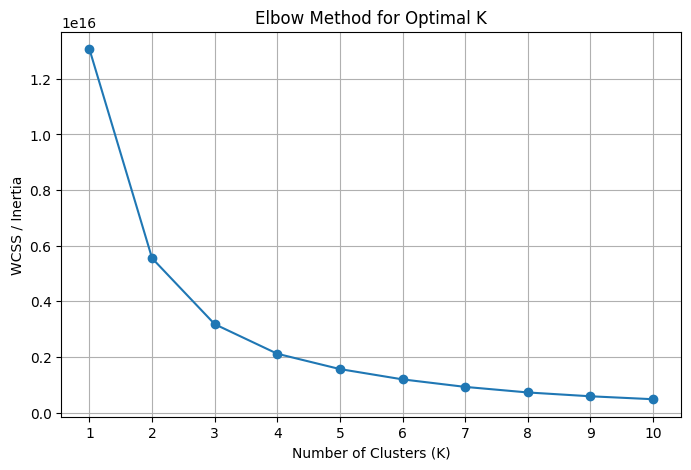

In [8]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Select numerical features for clustering
X = insurance_dataset[
    [
        'AMT_CREDIT',
        'AMT_ANNUITY',
        'AMT_GOODS_PRICE',
        'DAYS_BIRTH',
        'DAYS_EMPLOYED',
        'DAYS_REGISTRATION',
        'DAYS_ID_PUBLISH',
        'CNT_FAM_MEMBERS'
    ]
]

# Elbow Method
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    wcss.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS / Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(range(1, 11))
plt.grid()

plt.show()

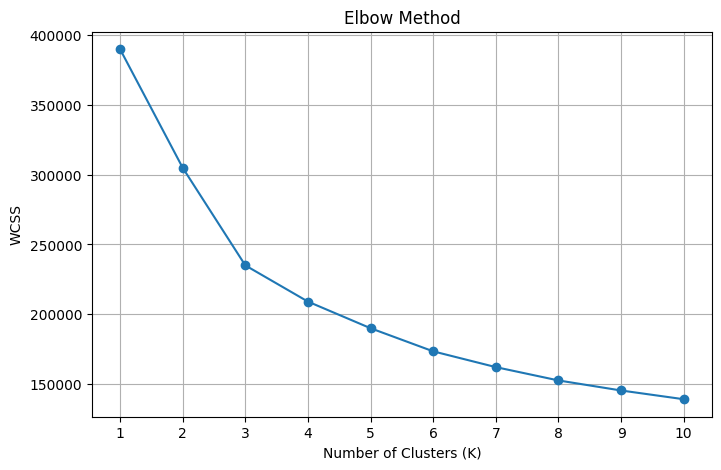

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Features used for clustering
features = [
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'DAYS_REGISTRATION',
    'DAYS_ID_PUBLISH',
    'CNT_FAM_MEMBERS'
]

X = insurance_dataset[features]

# Standardize the data
X_scaled = StandardScaler().fit_transform(X)

# Find WCSS for different values of K
wcss = []

for clusters in range(1, 11):
    kmeans = KMeans(
        n_clusters=clusters,
        n_init=10,
        random_state=42
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Display Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, 'o-')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [10]:
from sklearn.cluster import KMeans

# Build K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train and predict clusters
kmeans_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to dataset
insurance_dataset['KMeans_Cluster'] = kmeans_labels

# Check number of records in each cluster
print(insurance_dataset['KMeans_Cluster'].value_counts().sort_index())

KMeans_Cluster
0    29837
1     9091
2     9816
Name: count, dtype: int64


In [11]:
X_scaled[0:100]

array([[ 1.42475439e-01, -5.53579715e-01, -3.74772411e-02,
        -7.33476884e-01, -4.83656422e-01, -5.69579108e-02,
         1.42724091e+00, -1.64829867e-01],
       [-8.04537114e-01, -7.52831289e-01, -8.39361941e-01,
        -4.61392008e-01, -4.98481805e-01, -1.16826431e+00,
         9.10437016e-01, -1.64829867e-01],
       [ 4.01002378e-01,  2.52006551e+00,  4.97112559e-01,
        -9.17717875e-01, -4.98405600e-01,  7.86092412e-01,
        -2.87579416e-01, -1.64829867e-01],
       [ 2.89622084e+00,  1.22366563e+00,  3.30370901e+00,
         4.83623263e-01, -4.80448874e-01,  8.35352447e-01,
        -7.36835578e-01,  2.08131691e+00],
       [ 2.97650716e-01,  1.65018697e-01,  4.83747814e-01,
         6.99996623e-01, -4.82700392e-01,  2.72380613e-01,
        -7.71246689e-01,  9.58243522e-01],
       [ 1.21224888e+00,  3.23239623e-01,  1.03170236e+00,
        -5.86222792e-01, -5.50717034e-01, -3.23243589e-01,
         6.52990932e-01, -1.64829867e-01],
       [-4.79467951e-02, -4.563426

In [12]:
from sklearn.preprocessing import StandardScaler

features = [
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'DAYS_REGISTRATION',
    'DAYS_ID_PUBLISH',
    'CNT_FAM_MEMBERS'
]

X = insurance_dataset[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [13]:
from sklearn.metrics import silhouette_score

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("NaN values:", X_scaled != X_scaled)

NaN values: [[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


In [17]:
import numpy as np

print("NaN values:", np.isnan(X_scaled).sum())

NaN values: 0


In [18]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print(kmeans_labels)

[0 0 2 ... 0 0 0]


In [19]:
from sklearn.metrics import silhouette_score

kmeans_score = silhouette_score(X_scaled, kmeans_labels)

print("K-Means Silhouette Score:", kmeans_score)

K-Means Silhouette Score: 0.28306641357058365


Agglomorative Clustering

In [ ]:
from sklearn.cluster import AgglomerativeClustering
# Build Agglomerative model
agg_model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

# Train and predict clusters
agg_labels = agg_model.fit_predict(X_scaled)


In [ ]:
from sklearn.cluster import AgglomerativeClustering

sample_data = X_scaled[:5000]

agg = AgglomerativeClustering(
    n_clusters=3
)

agg_labels = agg.fit_predict(sample_data)

print(agg_labels)

[0 0 2 ... 0 0 0]


In [ ]:
from sklearn.metrics import silhouette_score

agg_score = silhouette_score(
    sample_data,
    agg_labels,
    metric='euclidean'
)

print("Agglomerative Silhouette Score:", agg_score)

Agglomerative Silhouette Score: 0.28074796097726473


In [ ]:
X_scaled.shape

(48744, 8)

In [ ]:
from sklearn.metrics import pairwise_distances

In [ ]:
pip install validclust

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from validclust import dunn

In [ ]:
from sklearn.metrics import pairwise_distances

In [4]:
from sklearn.preprocessing import StandardScaler

features = [
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'DAYS_REGISTRATION',
    'DAYS_ID_PUBLISH',
    'CNT_FAM_MEMBERS'
]

X = insurance_dataset[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(48744, 8)


In [8]:
from sklearn.cluster import AgglomerativeClustering

# Select the same 5,000 rows
sample_data = X_scaled[:5000]

# Build Agglomerative model
agg = AgglomerativeClustering(
    n_clusters=3
)

# Create cluster labels
agg_labels = agg.fit_predict(sample_data)

print("Agglomerative clustering completed")
print("Number of labels:", len(agg_labels))

Agglomerative clustering completed
Number of labels: 5000


In [9]:
from sklearn.metrics import silhouette_score

agg_score = silhouette_score(
    sample_data,
    agg_labels
)

print("Agglomerative Silhouette Score:", agg_score)

Agglomerative Silhouette Score: 0.28074796097726473


In [12]:
from sklearn.metrics import pairwise_distances
from validclust import dunn

ag_distance = pairwise_distances(
    sample_data,
    metric='euclidean'
)

ag_dunn = dunn(
    ag_distance,
    agg_labels
)

print("Agglomerative Dunn Index:", ag_dunn)

Agglomerative Dunn Index: 0.038819217034247476


DB SCAN Clustering Algorithm

In [16]:
from sklearn.cluster import DBSCAN
db = DBSCAN(eps=0.5, min_samples=5)
db_labels=db.fit_predict(X_scaled)
print("number of unique clusters", np.unique(db_labels))
print("total number of rows", len(db_labels))
insurance_dataset['DBSCAN cluster'] = db_labels
insurance_dataset['DBSCAN cluster'].value_counts()

number of unique clusters [ -1   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16
  17  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34
  35  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52
  53  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70
  71  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88
  89  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106
 107 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124
 125 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142
 143 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160
 161 162 163 164 165 166 167 168 169 170 171]
total number of rows 48744


DBSCAN cluster
 0      17416
-1       7782
 1       6288
 3       5932
 4       5129
        ...  
 113        3
 120        3
 104        3
 153        2
 155        1
Name: count, Length: 173, dtype: int64

In [24]:
from sklearn.metrics import silhouette_score
db_score = silhouette_score(
    X_scaled,
    db_labels,
    metric='euclidean'
)
print("DBScan Silhouette Score:", db_score)

DBScan Silhouette Score: -0.31155373591555485


In [18]:
db_distance=pairwise_distances(
    X_scaled[:30000],
    metric='euclidean'
)
db_dunn=dunn(
    db_distance,
    db_labels[:30000]
)
print("DBScan Dunn Index:",db_dunn)

DBScan Dunn Index: 0.00579913346147037


Mean Shift Clustering

In [22]:
from sklearn.cluster import MeanShift
import numpy as np

# Use 5,000 rows because Mean Shift is computationally expensive
sample_data = X_scaled[:5000]

# Apply Mean Shift
ms = MeanShift()

ms_labels = ms.fit_predict(sample_data)

# Display results
print("number of unique clusters:", np.unique(ms_labels))
print("total number of rows:", len(ms_labels))

# Store cluster labels for the sampled rows
insurance_dataset.loc[:4999, 'MeanShift cluster'] = ms_labels

# Display cluster counts
print("\nMean Shift Cluster Counts:")
print(insurance_dataset['MeanShift cluster'].value_counts())

number of unique clusters: [0 1 2]
total number of rows: 5000

Mean Shift Cluster Counts:
MeanShift cluster
0.0    4975
1.0      23
2.0       2
Name: count, dtype: int64


In [25]:
from sklearn.metrics import silhouette_score

ms_score = silhouette_score(
    sample_data,
    ms_labels,
    metric='euclidean'
)

print("Mean shift Silhouette Score:", ms_score)

Mean shift Silhouette Score: 0.45092537225110807


In [26]:
ms_distance=pairwise_distances(
    X_scaled[0:25000],
    metric='euclidean'
)
ms_dunn=dunn(
    ms_distance,
    ms_labels[0:25000]
)
print("Mean shift Dunn Index:",db_dunn)

Mean shift Dunn Index: 0.00579913346147037


K Modes Clustering

In [27]:
pip install kmodes

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
insurance_dataset.shape

(48744, 125)

In [31]:
from kmodes.kmodes import KModes
import numpy as np

insurancecat_dataset = insurance_dataset[
    [
        'NAME_CONTRACT_TYPE',
        'CODE_GENDER',
        'FLAG_OWN_CAR',
        'FLAG_OWN_REALTY',
        'NAME_INCOME_TYPE',
        'NAME_EDUCATION_TYPE',
        'NAME_FAMILY_STATUS',
        'NAME_HOUSING_TYPE',
        'OCCUPATION_TYPE',
        'ORGANIZATION_TYPE'
    ]
].copy()

# Fill missing categorical values
insurancecat_dataset = insurancecat_dataset.fillna('Unknown')

kmod = KModes(
    n_clusters=5,
    init='huang',
    random_state=42
)

kmod_labels = kmod.fit_predict(insurancecat_dataset)

print("number of unique clusters", np.unique(kmod_labels))

print("total number of rows", len(kmod_labels))

insurance_dataset['KModes cluster'] = kmod_labels

print(insurance_dataset['KModes cluster'].value_counts())

print("Dataset shape:", insurance_dataset.shape)

number of unique clusters [0 1 2 3 4]
total number of rows 48744
KModes cluster
2    13088
1    11910
0    11376
3     9276
4     3094
Name: count, dtype: int64
Dataset shape: (48744, 126)


In [32]:
insurance1_encoded = pd.get_dummies(
    insurancecat_dataset
).astype(int)

In [36]:
from sklearn.metrics import silhouette_score

# Use the same 5,000 rows for data and cluster labels
sample_encoded = insurance1_encoded[:5000]
sample_labels = kmod_labels[:5000]

kmod_silhouette = silhouette_score(
    sample_encoded,
    sample_labels,
    metric='hamming'
)

print("K modes Silhouette Score:", kmod_silhouette)

K modes Silhouette Score: 0.17472803690930178


In [34]:
insurance1_encoded.shape

(48744, 108)

In [35]:
from sklearn.metrics import pairwise_distances
from validclust import dunn

kmod_distance = pairwise_distances(
    insurance1_encoded[1:10000],
    metric='hamming'
)

kmod_dunn = dunn(
    kmod_distance,
    kmod_labels[1:10000]
)

print("Kmodes Dunn Index:", kmod_dunn)

Kmodes Dunn Index: 0.1


K-Prototype Clustering 

In [37]:
insurancepro_dataset = [[insurance_dataset, insurancecat_dataset]]

In [38]:
insurancecat_dataset.columns

Index(['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
       'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE'],
      dtype='object')

In [39]:
categorical_columns = [
    insurancecat_dataset.columns.get_loc(col)
    for col in insurancecat_dataset.columns
]

print("Categorical column positions:", categorical_columns)

Categorical column positions: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [44]:
from kmodes.kprototypes import KPrototypes
import numpy as np

# Use 5,000 rows because K-Prototypes is computationally expensive
kproto_sample = kproto_dataset.iloc[:5000].copy()

# Convert to NumPy array
kproto_data = kproto_sample.values

# Categorical column positions
categorical_positions = list(
    range(
        len(numeric_columns),
        len(numeric_columns) + len(categorical_columns_names)
    )
)

# Apply K-Prototypes
kp = KPrototypes(
    n_clusters=5,
    init='Huang',
    random_state=42
)

kp_labels = kp.fit_predict(
    kproto_data,
    categorical=categorical_positions
)

print("Unique Clusters:", np.unique(kp_labels))
print("Total Rows:", len(kp_labels))

# Store cluster labels for the sampled rows
insurance_dataset.loc[:4999, 'KPrototypes cluster'] = kp_labels

print("\nKPrototypes Cluster Counts:")
print(insurance_dataset['KPrototypes cluster'].value_counts())

Unique Clusters: [0 1 2 3 4]
Total Rows: 5000

KPrototypes Cluster Counts:
KPrototypes cluster
1.0    1640
4.0    1391
2.0     983
3.0     767
0.0     219
Name: count, dtype: int64


In [45]:
categorical_names = [
    'NAME_CONTRACT_TYPE',
    'CODE_GENDER',
    'FLAG_OWN_CAR',
    'FLAG_OWN_REALTY',
    'NAME_INCOME_TYPE',
    'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS',
    'NAME_HOUSING_TYPE',
    'OCCUPATION_TYPE',
    'ORGANIZATION_TYPE'
]

insurancepro_kp_encoded = pd.get_dummies(
    insurancecat_dataset
).astype(float)

In [46]:
from sklearn.metrics import silhouette_score

kp_silhouette = silhouette_score(
    insurancepro_kp_encoded[:5000],
    kp_labels,
    metric='euclidean'
)

print("K Prototype silhouette score:", kp_silhouette)

K Prototype silhouette score: 0.027883407787424062


In [47]:
from sklearn.metrics import pairwise_distances
from validclust import dunn

kp_distance = pairwise_distances(
    insurancepro_kp_encoded[:5000],
    metric='euclidean'
)

kp_dunn = dunn(
    kp_distance,
    kp_labels
)

print("K Prototype Dunn Index:", kp_dunn)

K Prototype Dunn Index: 0.0
